<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m10-0-homes-preview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data of Homes: A Preview of Modules 10 to 12

In September, you collected listings of homes for sale in seven zip codes around the Twin Cities. Today we use these data to preview what is left in the course: comparing several groups (Module 10), fitting a line (Module 11), and models with several explanatory variables (Module 12).

Our question for today: **how do list prices differ across the Twin Cities, and why?**

Cells with `___` are yours to complete. Run the cells in order with **Shift + Enter**.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import json, urllib.request
import geopandas as gpd

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/data_of_homes_f26.csv")
df["zip"] = df["zip"].astype(str)
city = {"55075": "South St. Paul", "55122": "Eagan", "55327": "Dayton", "55346": "Eden Prairie",
        "55404": "Minneapolis", "55428": "New Hope", "55441": "Plymouth"}
df["city"] = df["zip"].map(city)
df[["zip", "city", "property_type", "list_price", "sqft", "beds"]].head()

,zip,city,property_type,list_price,sqft,beds
0,55075,South St. Paul,Single Family,424300,2702,4
1,55075,South St. Paul,Single Family,375000,2167,3
2,55075,South St. Paul,Single Family,369900,1504,3
3,55075,South St. Paul,Single Family,349900,2064,4
4,55075,South St. Paul,Single Family,325000,1563,3


## 1. Where are the homes?

The map shows the seven zip codes in our sample, among all the zip codes of the Twin Cities area.

**Question to you:** before looking at the data, make two guesses. In which zip code are the most expensive homes? In which zip code is the highest percentage of condos?

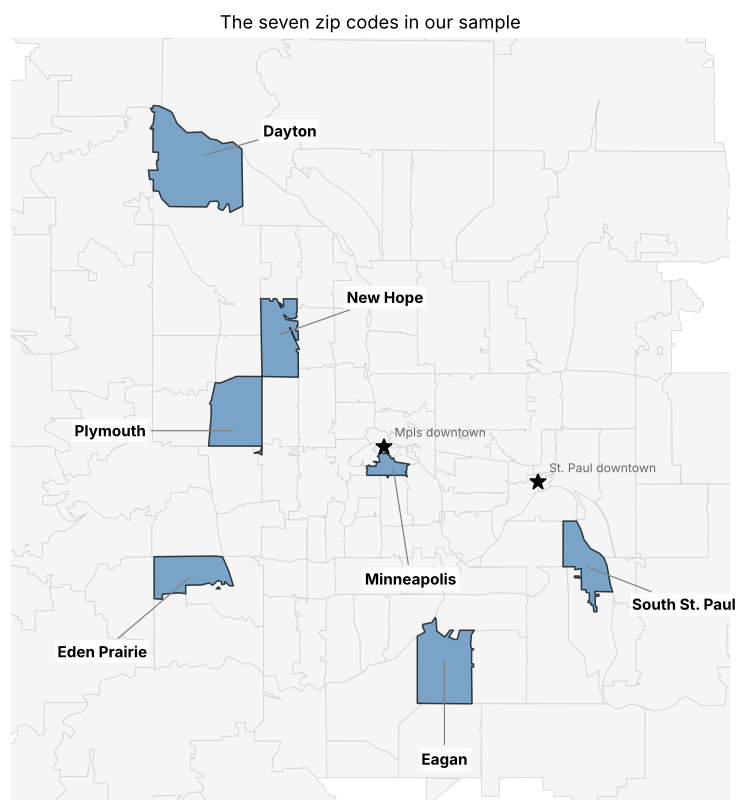

In [ ]:
with urllib.request.urlopen("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/twin_cities_zips.geojson") as f:
    zips_gdf = gpd.GeoDataFrame.from_features(json.load(f)["features"], crs="EPSG:4326")
zips_gdf["zip"] = zips_gdf["zip"].astype(str)
sample_zips = zips_gdf[zips_gdf["sample"]]

def zip_map(values=None, label="", cmap="YlOrRd", fmt="{:,.0f}", vmin=None):
    offsets = {"55327": (0.10, 0.02), "55428": (0.12, 0.03), "55441": (-0.14, 0.0), "55346": (-0.10, -0.06),
               "55404": (0.02, -0.09), "55122": (0.0, -0.08), "55075": (0.11, -0.03)}
    fig, ax = plt.subplots(figsize=(9, 9))
    zips_gdf.plot(ax=ax, color="whitesmoke", edgecolor="lightgray", linewidth=0.5)
    if values is None:
        sample_zips.plot(ax=ax, color="steelblue", alpha=0.7, edgecolor="black")
    else:
        sample_zips.assign(value=sample_zips["zip"].map(values)).plot(
            column="value", cmap=cmap, vmin=vmin, edgecolor="black", legend=True, ax=ax,
            legend_kwds={"label": label, "shrink": 0.5})
    for _, r in sample_zips.iterrows():
        pt = r.geometry.representative_point()
        dx, dy = offsets[r["zip"]]
        txt = city[r["zip"]] if values is None else city[r["zip"]] + "\n" + fmt.format(values[r["zip"]])
        ax.annotate(txt, xy=(pt.x, pt.y), xytext=(pt.x + dx, pt.y + dy), ha="center", va="center",
                    fontsize=10, fontweight="bold", arrowprops=dict(arrowstyle="-", color="gray", lw=0.8),
                    bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=1.5))
    for name, lon, lat in [("Mpls downtown", -93.265, 44.978), ("St. Paul downtown", -93.093, 44.950)]:
        ax.plot(lon, lat, marker="*", color="black", markersize=11)
        ax.text(lon + 0.012, lat + 0.008, name, fontsize=8, color="dimgray")
    ax.set_xlim(-93.68, -92.88); ax.set_ylim(44.70, 45.30)
    ax.set_axis_off()
    ax.set_title("The seven zip codes in our sample" if values is None else label)
    plt.show()

zip_map()

**Exercise:** complete the code to compute the number of homes, the mean list price, and the median list price in each zip code.

In [ ]:
zip_summary = df.groupby("___")["___"].agg(["count", "mean", "median"])
zip_summary.sort_values("mean", ascending=False)

**Exercise:** complete the code to find the share of each property type in each zip code. The option `normalize="index"` turns counts into shares within each row.

In [ ]:
pd.crosstab(df["city"], df["___"], normalize="___").round(2)

Now the same numbers on the map. How good were your guesses?

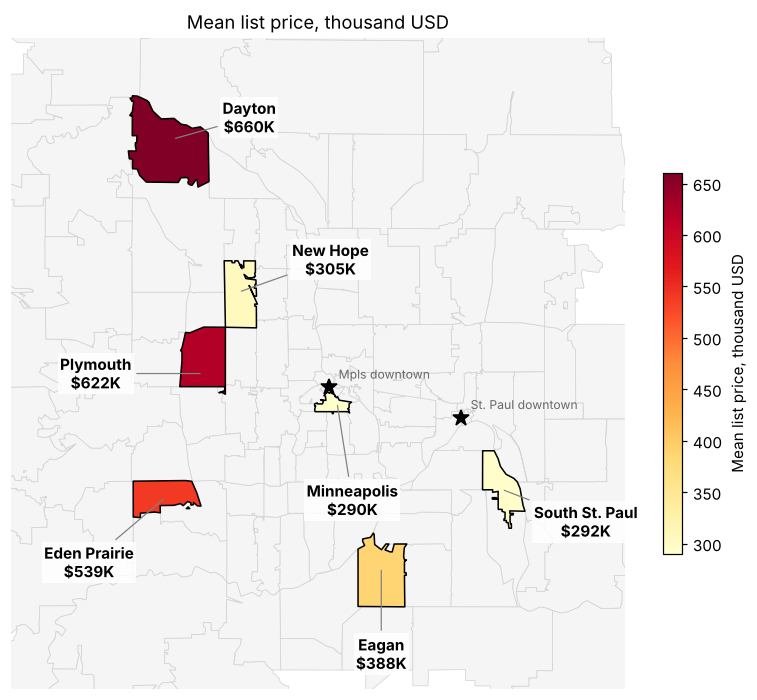

In [ ]:
zip_map(df.groupby("zip")["list_price"].mean() / 1000, "Mean list price, thousand USD", fmt="${:,.0f}K")

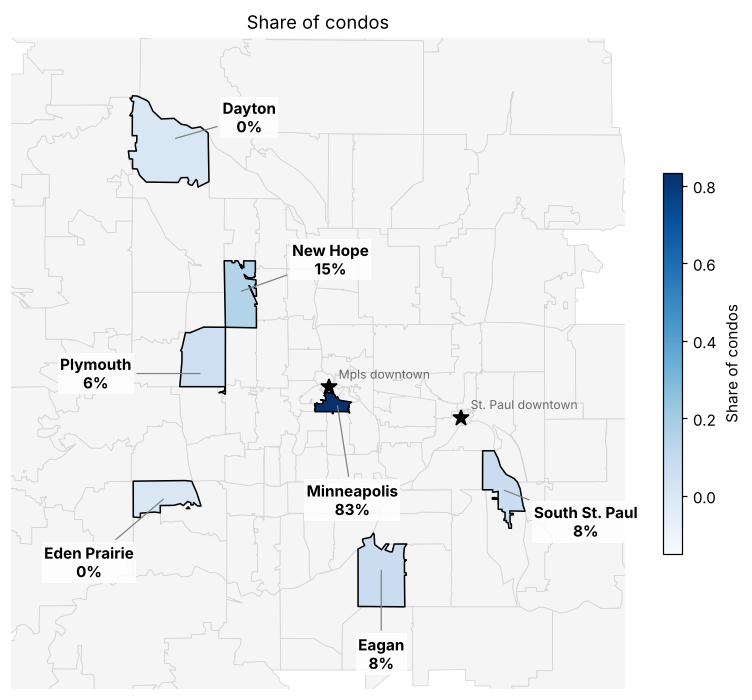

In [ ]:
condo_share = (df["property_type"] == "Condo").groupby(df["zip"]).mean()
zip_map(condo_share, "Share of condos", cmap="Blues", fmt="{:.0%}", vmin=-0.15)

## 2. Comparing several groups (Module 10)

**What it is used for:** comparing the mean of a variable across several groups: sales across regions, defect rates across suppliers, conversion rates across three website designs.

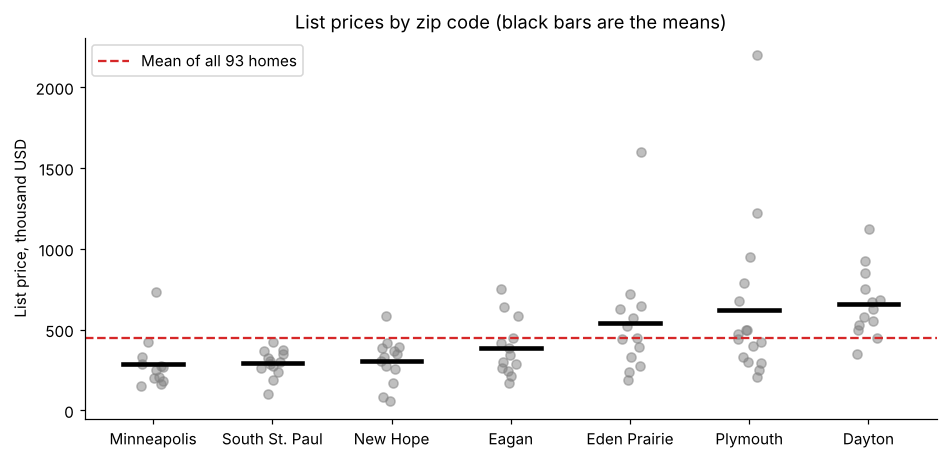

In [ ]:
order = zip_summary.sort_values("mean").index
fig, ax = plt.subplots(figsize=(10, 4.5))
for i, c in enumerate(order):
    p = df.loc[df["city"] == c, "list_price"] / 1000
    ax.scatter(np.full(len(p), i) + np.random.default_rng(i).uniform(-0.1, 0.1, len(p)), p, alpha=0.5, color="gray")
    ax.plot([i - 0.25, i + 0.25], [p.mean()] * 2, color="black", lw=3)
ax.axhline(df["list_price"].mean() / 1000, color="tab:red", ls="--", label="Mean of all 93 homes")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("List price, thousand USD"); ax.set_title("List prices by zip code (black bars are the means)"); ax.legend()
plt.show()

### Vocabulary

- **Response variable**, often referred to as the **dependent variable** (DV), is a variable of interest that a researcher is trying to explain or predict using one or more **explanatory variables**, also known as **independent variables**.
- **Factor** is a qualitative explanatory variable. Its values are called **levels**; in an experiment, they are called **treatments**.
- **Experimental units** are the objects on which the response is measured.
- In an **experiment**, the researcher assigns the treatments to the units, ideally at random. In an **observational study**, the units end up in the groups on their own, and the researcher only observes them.

**Question to you:** in our comparison of prices across zip codes, what is the response variable? What is the factor, and what are its levels? What are the units? Is this an experiment?

A difference between groups lets us **predict**: if a home is in Plymouth, it is probably more expensive than a home in South St. Paul. It does not by itself tell us what happens if we **intervene**. A convenience store sells more umbrellas on rainy days, but putting umbrellas on sale will not make it rain. Here we know how rain works. In business, our intuition about how things work is often less reliable, and the design of the study has to do the work.

**Question to you:** for each study below, is it an experiment or an observational study? What is the experimental unit? Would a causal conclusion be justified?

1. A bank randomly assigns 12 cohorts of new tellers (8 tellers in each) to three training formats and records each teller's average transaction time after 30 days.
2. A retailer finds that customers who received discount coupons spent more the following month than customers who did not. The coupons were sent to members of the loyalty program.
3. eBay paid search engines to show an ad whenever someone searched for "eBay". Customers who clicked the ad bought a lot. In 2012, eBay turned the ads off on Yahoo and Microsoft but kept them on Google, and almost all of the traffic simply came through the free search link instead.

### Between and within

Every home's price differs from the overall mean for two reasons:

- its zip code has a higher or lower mean than the others: variation **between** groups;
- the home differs from other homes in the same zip code: variation **within** groups.

**Exercise:** split each home's deviation from the overall mean into these two parts.

In [ ]:
df["zip_mean"] = df.groupby("zip")["list_price"].transform("___")
df["between"] = df["zip_mean"] - df["list_price"].___()
df["within"] = df["list_price"] - df["___"]
df[["city", "list_price", "zip_mean", "between", "within"]].head()

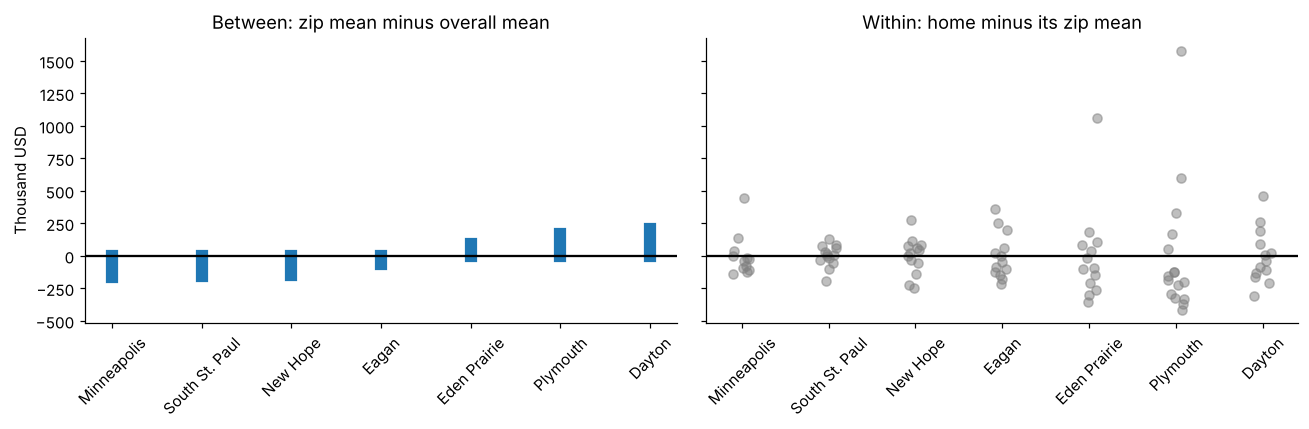

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for i, c in enumerate(order):
    g = df[df["city"] == c]
    axes[0].plot([i, i], [0, g["between"].iloc[0] / 1000], color="tab:blue", lw=8)
    axes[1].scatter(np.full(len(g), i) + np.random.default_rng(i).uniform(-0.1, 0.1, len(g)), g["within"] / 1000, color="gray", alpha=0.5)
for ax, t in zip(axes, ["Between: zip mean minus overall mean", "Within: home minus its zip mean"]):
    ax.axhline(0, color="black"); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45); ax.set_title(t)
axes[0].set_ylabel("Thousand USD")
plt.tight_layout(); plt.show()

**Analysis of variance (ANOVA)** compares the size of these two kinds of variation. Their ratio is called **F**. If all zip codes had the same population mean, the between part would only be an echo of the within part, and F would be close to 1. You will learn to read the full output in the Module 10 videos; here is the one-line version.

In [ ]:
f_stat, p_value = stats.f_oneway(*[g["list_price"] for _, g in df.groupby("zip")])
print(f"F = {f_stat:.2f}, p-value = {p_value:.4f}")

F = 4.41, p-value = 0.0006


A p-value this small means that if all seven zip codes had the same mean price, differences between the sample means this large would almost never happen by chance.

### Can we trust it?

ANOVA assumes that the observations are independent, that the response is roughly normal within each group, and that the groups have similar spreads. We already know from the design that the first assumption is questionable: we sampled zip codes first and homes within them. Now look at the spreads.

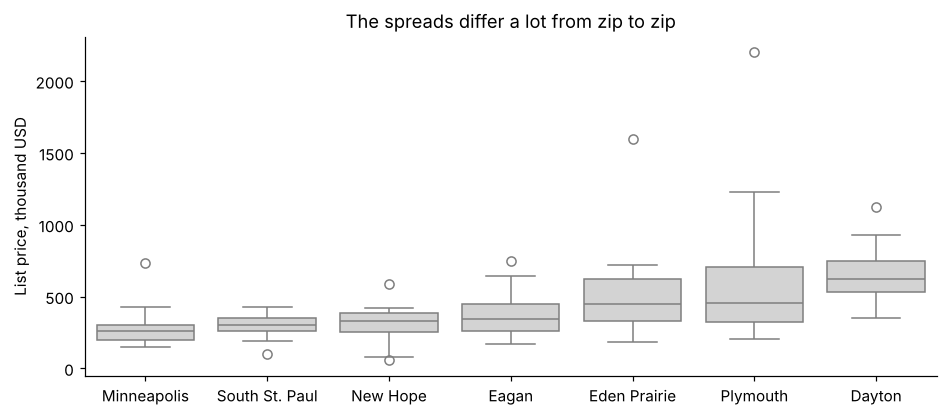

Largest SD / smallest SD: 5.9


In [ ]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["city"], y=df["list_price"] / 1000, order=order, color="lightgray")
plt.ylabel("List price, thousand USD"); plt.xlabel(""); plt.title("The spreads differ a lot from zip to zip")
plt.show()
sds = df.groupby("city")["list_price"].std()
print(f"Largest SD / smallest SD: {sds.max() / sds.min():.1f}")

A common rule of thumb asks for the largest standard deviation to be less than about twice the smallest. Here the assumption is clearly violated, and prices are skewed to the right. In practice we would use the **Kruskal–Wallis test**, which compares the groups using the ranks of the observations, so it does not need equal spreads or normal distributions.

In [ ]:
h_stat, p_kw = stats.kruskal(*[g["list_price"] for _, g in df.groupby("zip")])
print(f"Kruskal-Wallis p-value = {p_kw:.2e}")

Kruskal-Wallis p-value = 1.41e-05


**Question to you:** one Plymouth home is listed at $2.2 million, far above everything else. Should we remove it from the data? What would you check first?

In [ ]:
df.sort_values("list_price", ascending=False)[["city", "address", "list_price", "sqft", "property_type"]].head(3)

,city,address,list_price,sqft,property_type
77,Plymouth,205 Deerwood Ln N Plymouth MN 55441,2199900,5667,Single Family
39,Eden Prairie,7100 Highland Ct Eden Prairie MN 55346,1600000,3562,Single Family
78,Plymouth,5 Deerwood Ln N Plymouth MN 55441,1224900,4101,Single Family


In [ ]:
without = df[df["list_price"] < 2_000_000]
p_without = stats.f_oneway(*[g["list_price"] for _, g in without.groupby("zip")]).pvalue
print(f"ANOVA p-value with the $2.2M home:    {p_value:.5f}")
print(f"ANOVA p-value without the $2.2M home: {p_without:.5f}")

ANOVA p-value with the $2.2M home:    0.00062
ANOVA p-value without the $2.2M home: 0.00006


Removing the most expensive home makes the zip codes look **more** different, because that one home inflates the variation within Plymouth. A value should not be removed just because it is extreme: it may be a real listing, and here it is. Better options are to check the record, to use methods that are less sensitive to extreme values (the median, the Kruskal–Wallis test, the logarithm of price), and to report the results with and without it.

## 3. Is it the place, or the type of home?

Look at Eden Prairie and Eagan.

In [ ]:
two = df[df["city"].isin(["Eden Prairie", "Eagan"])].copy()
two["type"] = np.where(two["property_type"] == "Single Family", "Single family", "Condo or townhouse")
two.groupby("city")["list_price"].mean().round(0)

city
Eagan          388,261.00
Eden Prairie   538,953.00
Name: list_price, dtype: float64

**Exercise:** complete the code to compare the mean prices in the two cities **separately** for single-family homes and for condos and townhouses, and to count the homes of each type.

In [ ]:
print(two.pivot_table(values="list_price", index="city", columns="___", aggfunc="___").round(0))
print(pd.crosstab(two["city"], two["___"]))

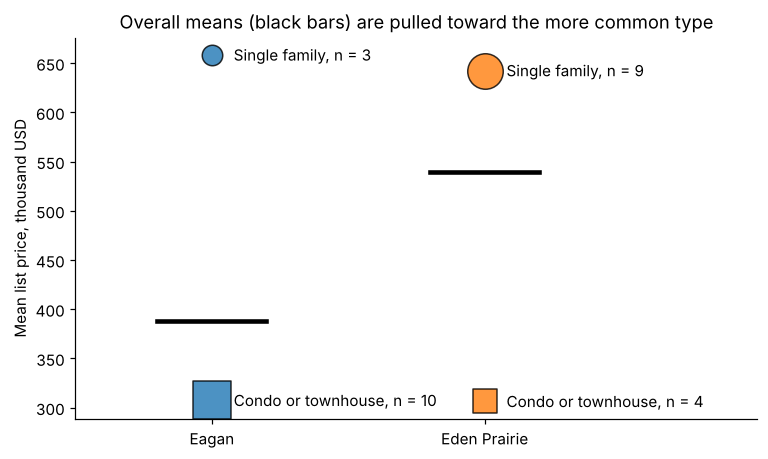

In [ ]:
means = two.pivot_table(values="list_price", index="city", columns="type", aggfunc="mean") / 1000
counts = pd.crosstab(two["city"], two["type"])
overall = two.groupby("city")["list_price"].mean() / 1000
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, c in enumerate(["Eagan", "Eden Prairie"]):
    for t, mk in zip(means.columns, ["s", "o"]):
        ax.scatter(j, means.loc[c, t], s=counts.loc[c, t] * 60, marker=mk, color="tab:blue" if c == "Eagan" else "tab:orange", edgecolor="black", alpha=0.8)
        ax.text(j + 0.08, means.loc[c, t], f"{t}, n = {counts.loc[c, t]}", va="center")
    ax.plot([j - 0.2, j + 0.2], [overall[c]] * 2, color="black", lw=3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Eagan", "Eden Prairie"]); ax.set_xlim(-0.5, 2.0)
ax.set_ylabel("Mean list price, thousand USD")
ax.set_title("Overall means (black bars) are pulled toward the more common type")
plt.show()

**Question to you:** Eden Prairie looks much more expensive overall, yet for each type of home Eagan is about the same or slightly higher. How can both be true?

A comparison that holds within every subgroup but reverses when the subgroups are combined is called **Simpson's paradox**. Here the difference between the two cities comes from the mix of homes, not from the location: most Eden Prairie listings are single-family homes, and most Eagan listings are not. With 13 homes per city these differences are small and uncertain, but the mechanism is what matters.

### Two factors at once

A **two-way ANOVA** compares the zip codes while taking the type of home into account. To keep it simple, we use two types: single-family and other.

**Exercise:** complete the formula so that the model includes both the zip code and the type of home.

In [ ]:
df["type"] = np.where(df["property_type"] == "Single Family", "Single family", "Other")
model = ols("list_price ~ C(zip) + C(___)", data=df).fit()
sm.stats.anova_lm(model, typ=2)

**Question to you:** both factors matter. Would we also need an **interaction**, that is, could the price premium of a single-family home be different in different zip codes? Look at your table of property types by zip code: can we even estimate a single-family premium in Minneapolis or in Dayton?

**Question to you:** if we do not suspect an interaction, does it still make sense to include the type of home? Think about what happened with Eden Prairie and Eagan.

## 4. Fitting a line (Module 11)

**What it is used for:** describing and predicting one quantitative variable from another: sales from advertising, delivery time from distance, cost from production volume.

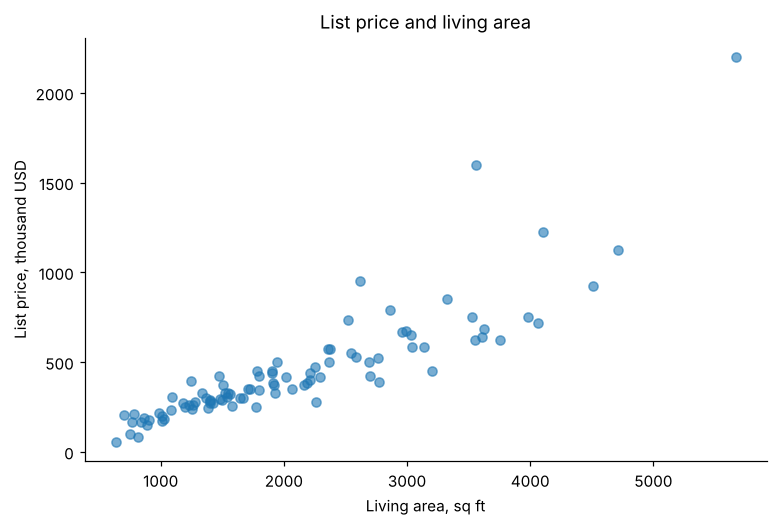

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["sqft"], df["list_price"] / 1000, alpha=0.6)
plt.xlabel("Living area, sq ft"); plt.ylabel("List price, thousand USD"); plt.title("List price and living area")
plt.show()

**Question to you:** what is the best way to draw a straight line through these points? What would make one line better than another?

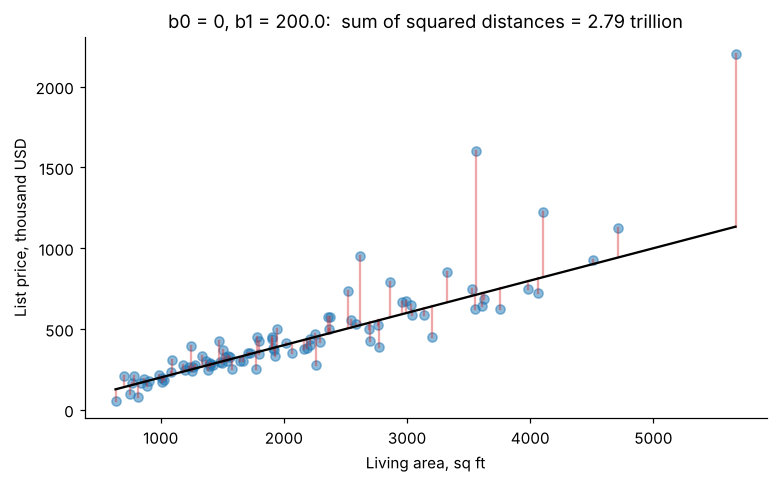

In [ ]:
def sse_line(b0, b1):
    pred = b0 + b1 * df["sqft"]
    sse = ((df["list_price"] - pred) ** 2).sum()
    xs = np.linspace(df["sqft"].min(), df["sqft"].max(), 100)
    plt.figure(figsize=(8, 4.5))
    plt.scatter(df["sqft"], df["list_price"] / 1000, alpha=0.5)
    for x, y, p in zip(df["sqft"], df["list_price"], pred):
        plt.plot([x, x], [y / 1000, p / 1000], color="tab:red", alpha=0.4)
    plt.plot(xs, (b0 + b1 * xs) / 1000, color="black")
    plt.xlabel("Living area, sq ft"); plt.ylabel("List price, thousand USD")
    plt.title(f"b0 = {b0:,.0f}, b1 = {b1:,.1f}:  sum of squared distances = {sse / 1e12:.2f} trillion")
    plt.show()

sse_line(b0=0, b1=200)

The red segments are the vertical distances from each home to the line: how far off the line is for that home. We measure the quality of a line by squaring these distances and adding them up. The **least squares line** is the line for which this **sum of squared errors** is as small as possible.

**Exercise:** try your own intercept `b0` (in USD) and slope `b1` (in USD per square foot). Who in the room can get the smallest sum?

In [ ]:
sse_line(b0=___, b1=___)

Software finds the least squares line for us. **Exercise:** complete the formula: list price explained by living area.

In [ ]:
line = ols("list_price ~ ___", data=df).fit()
print(line.params)
sse_line(line.params["Intercept"], line.params["sqft"])

**Exercise:** use the fitted line to estimate the list price of a 2,000 square foot home.

In [ ]:
estimate = line.params["Intercept"] + line.params["sqft"] * ___
print(f"Estimated list price: {estimate:,.0f} USD")

**Question to you:** how would you say the slope in words, in dollars and square feet? Does it tell us how much a homeowner would gain by building a 200 square foot addition?

## 5. Several explanatory variables (Module 12)

**What it is used for:** comparing like with like. Do employees with an MBA earn more than employees **with the same experience**? Do stores with self-checkout sell more than stores **of the same size**?

A regression can include a qualitative variable through a **dummy variable**: 1 for single-family homes, 0 for all others.

In [ ]:
df["single_family"] = (df["property_type"] == "Single Family").astype(int)
dummy_only = ols("list_price ~ single_family", data=df).fit()
both = ols("list_price ~ sqft + single_family", data=df).fit()
print(f"Single-family premium, ignoring size:         {dummy_only.params['single_family']:,.0f} USD")
print(f"Single-family premium, holding size constant: {both.params['single_family']:,.0f} USD")

Single-family premium, ignoring size:         293,741 USD
Single-family premium, holding size constant: 8,095 USD


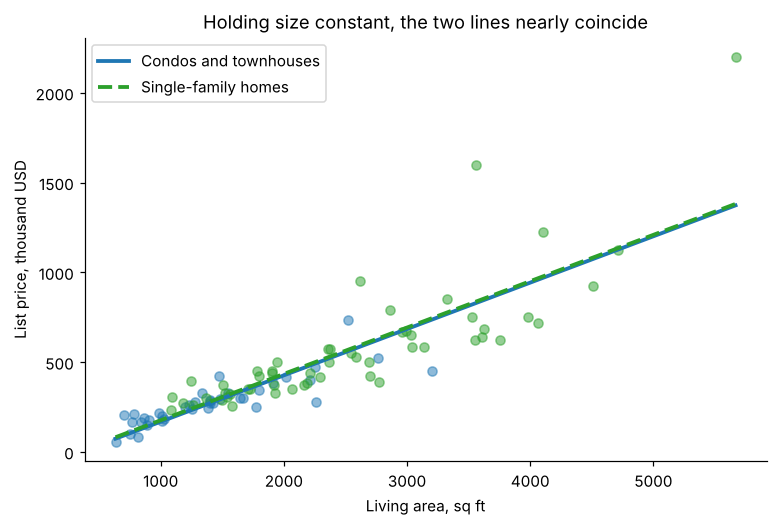

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
xs = np.linspace(df["sqft"].min(), df["sqft"].max(), 100)
for v, c, lab, ls in [(0, "tab:blue", "Condos and townhouses", "-"), (1, "tab:green", "Single-family homes", "--")]:
    g = df[df["single_family"] == v]
    ax.scatter(g["sqft"], g["list_price"] / 1000, alpha=0.5, color=c)
    ax.plot(xs, (both.params["Intercept"] + both.params["single_family"] * v + both.params["sqft"] * xs) / 1000, color=c, lw=2.5, ls=ls, label=lab)
ax.set_xlabel("Living area, sq ft"); ax.set_ylabel("List price, thousand USD")
ax.set_title("Holding size constant, the two lines nearly coincide"); ax.legend(); plt.show()

**Question to you:** which of the two numbers answers "how much more does a typical single-family listing cost?", and which answers "is a single-family home more expensive than a condo or townhouse of the same size?" Which one would a buyer need, and which one a builder?

## What comes next

- **Module 10** (this week): comparing groups with ANOVA, experiments and causality, two factors. Homework 10 is due Sunday, November 22.
- **Module 11** (Thanksgiving week): simple linear regression. Homework 11 is due Sunday, November 29.
- **Module 12**: multiple regression. Homework 12 is due Sunday, December 6.
- **December 7:** exam review and Test 4 on Modules 10 to 12. The practice problems and the AI tutor setup are on Canvas.